# Swin-T para classificação binária de mamografias: generalização entre datasets

Baseline com **Swin Transformer Tiny** (pré-treino ImageNet) para **Normal (0) vs Anormal (1 = benigno + maligno)**.

| Dataset | Imagens | Normais | Anormais |
|---|---|---|---|
| mini-MIAS | 318 | 207 (65,1 %) | 111 (34,9 %) |
| Mini-DDSM (Complete) | 3.716 | 2.408 (64,8 %) | 1.308 (35,2 %) |

**Protocolo**
1. **Exp. 1:** validação cruzada interna, 5-fold agrupada por paciente.
2. **Exp. 2:** treina em um dataset e testa no outro (nos dois sentidos, 3 sementes).
3. **Análise:** queda de AUC, IC 95 % por bootstrap de pacientes, ROC, matrizes de confusão e deslocamento de limiar.

> Limiar e early stopping nunca usam o teste. Saem de uma validação interna separada por paciente.

## 1. Setup

In [1]:
!pip install -q timm albumentations
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, hashlib, random, re, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm

import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from scipy import ndimage as ndi
from joblib import Parallel, delayed

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             f1_score, precision_score, accuracy_score)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")


def seed_everything(seed: int):
    # fixa todas as seeds
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE}")

Mounted at /content/drive
device: cuda


## 2. Configuração

Parâmetros em `CONFIG`. `QUICK_TEST=True` faz um teste rápido (2 épocas, 1 semente, 100 bootstraps).

In [ ]:
CONFIG = dict(
    # caminhos
    OUTPUT_DIR = "/content/drive/MyDrive/TCC/outputs_roi_clahe",
    CACHE_DIR  = "./cache",
    NPZ_PATH   = "/content/drive/MyDrive/TCC/dados_preprocessados_roi.npz",

    # pré-processamento
    IMG_SIZE         = 224,

    # modelo
    MODEL_NAME  = "swin_tiny_patch4_window7_224",
    POOLING     = "haar_trainable",            # 'patch_merging' (baseline) | 'haar' (Haar 2D fixa no lugar do concat 2x2) | 'haar_trainable' (idem, com filtros Haar treináveis)
    PRETRAINED  = True,
    NUM_CLASSES = 1,              # 1 logit + BCEWithLogitsLoss

    # fine-tuning em duas fases
    FREEZE_BACKBONE_EPOCHS = 5,  # épocas só com a cabeça
    HEAD_LR          = 3e-4,     # LR da cabeça
    BACKBONE_LR      = 1e-5,     # LR do backbone
    WAVELET_LR       = 1e-5,     # LR dos filtros wavelet treináveis (fase 2, sem weight decay)

    # treino
    BATCH_SIZE       = 32,
    EPOCHS           = 30,
    LEARNING_RATE    = 1e-4,
    WEIGHT_DECAY     = 0.05,
    USE_POS_WEIGHT   = True,
    USE_AMP          = True,      # só GPU
    GRAD_CLIP        = 1.0,
    EARLY_STOPPING   = True,
    PATIENCE         = 7,
    MIN_EPOCHS       = 5,
    ES_METRIC        = "val_auc", # 'val_auc' ou 'val_loss'
    THRESHOLD_METHOD = "youden",  # 'youden' ou 'f1'
    INNER_VAL_FRAC   = 0.15,      # fração do treino (por paciente) usada como validação

    # experimentos
    N_SPLITS  = 5,
    EXP1_SEED = 42,
    SEEDS     = [42, 123, 999],
    N_BOOT    = 1000,
    BOOT_SEED = 0,

    # sistema
    NUM_WORKERS = 0,              # 0 evita problemas no Windows
    N_JOBS      = -1,

    QUICK_TEST = False,
)

if CONFIG["QUICK_TEST"]:
    CONFIG.update(EPOCHS=2, PATIENCE=2, MIN_EPOCHS=1, SEEDS=CONFIG["SEEDS"][:1], N_BOOT=100)

assert CONFIG["NUM_CLASSES"] == 1, "Usa 1 logit (BCEWithLogitsLoss)."

assert CONFIG["POOLING"] in {"patch_merging", "haar", "haar_trainable"}
CONFIG["OUTPUT_DIR"] += "_" + CONFIG["POOLING"]      # cada variante salva na própria pasta

OUT = Path(CONFIG["OUTPUT_DIR"])
OUT.mkdir(parents=True, exist_ok=True)
Path(CONFIG["CACHE_DIR"]).mkdir(parents=True, exist_ok=True)

## 3. Dados e pré-processamento

Mesmo pipeline nos dois datasets: segmenta a mama (Otsu), põe a parede torácica à esquerda e recorta uma **janela quadrada (ROI)** de 30 % da altura da mama, redimensionada para 224×224. Augmentation só no treino, sem flip horizontal.

- **Com coordenada da lesão:** janela centrada nela. MIAS: centro da anomalia no `mias_info`. DDSM: centroide da máscara (`_Mask.jpg`), maior lesão.
- **Sem coordenada** (normais e anormais do DDSM sem máscara): janela de mesmo tamanho, centro sorteado no tecido da mama (semente fixa). O tamanho do recorte não distingue as classes.

O dataset é gerado por `gerar_dataset_roi.py` (já com CLAHE) e carregado do `.npz`. As funções desta seção são as do script e só rodam na geração.

In [5]:
# ---- Dataset, augmentation e DataLoader ----
class MammoDataset(Dataset):
    # X: (N, H, W) uint8 já pré-processado; idx: índices deste subconjunto
    def __init__(self, X, y, idx, transform=None):
        self.X, self.y, self.idx, self.transform = X, y, np.asarray(idx), transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = np.repeat(self.X[j][..., None], 3, axis=-1)        # 1 canal -> 3
        if self.transform is not None:
            img = self.transform(image=img)["image"]
        return img, torch.tensor(self.y[j], dtype=torch.float32)


IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])
eval_tf = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])


def make_loader(X, y, idx, train, seed=0):
    g = torch.Generator().manual_seed(seed)
    ds = MammoDataset(X, y, idx, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=train, drop_last=False,
                      num_workers=CONFIG["NUM_WORKERS"], pin_memory=(DEVICE.type == "cuda"),
                      generator=g if train else None, persistent_workers=CONFIG["NUM_WORKERS"] > 0)

In [6]:
# carrega imagens 224x224, rótulos e id do paciente
assert Path(CONFIG["NPZ_PATH"]).exists(), "Gere o .npz com gerar_dataset_roi.py e suba para o Drive."
z = np.load(CONFIG["NPZ_PATH"], allow_pickle=True)
DATA = {n: dict(df=None, X=z[f"{n}_X"], y=z[f"{n}_y"], groups=z[f"{n}_g"].astype(str)) for n in ["mias", "ddsm"]}

print({n: (d["X"].shape, int(d["y"].sum())) for n, d in DATA.items()})

{'mias': ((318, 224, 224), 111), 'ddsm': ((3716, 224, 224), 1308)}


## 4. Modelo

`swin_tiny_patch4_window7_224` (timm, pesos ImageNet), cabeça trocada por 1 logit, com `BCEWithLogitsLoss`.

**Fine-tuning em duas fases:**
1. Treina só a cabeça por `FREEZE_BACKBONE_EPOCHS` épocas.
2. Descongela tudo: LR menor no backbone (`BACKBONE_LR`), maior na cabeça (`HEAD_LR`).

A cabeça é separada com `get_classifier()` do timm, então vale também para CNNs timm.

**Modificação: `PatchMerging` → wavelet Haar treinável (`haar_trainable`).** O `PatchMerging` do Swin (concat dos 4 vizinhos 2×2 → `norm` → `reduction` Linear 4C→2C) tem o concat trocado por uma **Haar 2D de 1 nível com filtros treináveis** (LL, LH, HL, HH, cada uma com C canais, metade da resolução). As 4 bandas são concatenadas em 4C canais, ou seja, o mesmo formato do concat original, e seguem para a `norm` e a `reduction` **pré-treinadas**, que são mantidas. Os filtros 1D `lo` e `hi` (2 coeficientes cada, por camada de merging) são `nn.Parameter` e são **inicializados** com a Haar (`pywt.Wavelet('haar')`). Os 4 filtros 2D são reconstruídos a cada forward por produto externo, então a estrutura separável é mantida. Eles aprendem sem restrição de ortogonalidade, sem weight decay e com LR próprio (`WAVELET_LR`). São 4 parâmetros novos por camada (12 nas 3 camadas), e ficam congelados na fase 1 e liberados na fase 2, junto com o backbone e com a `norm`/`reduction` que vêm depois deles. Variantes via `CONFIG["POOLING"]`: `patch_merging` (baseline), `haar` (Haar fixa) e `haar_trainable` (Haar treinável).

In [7]:
import torch.nn.functional as F


class HaarPatchMerging(nn.Module):
    # Troca o concat 2x2 do PatchMerging por uma Haar 2D de 1 nível (LL, LH, HL, HH).
    # trainable_wavelet=False: filtros lo/hi fixos (buffer). True: lo/hi viram nn.Parameter (iniciados na Haar).
    # norm e reduction pré-treinados são reaproveitados (transfer learning).
    def __init__(self, old, trainable_wavelet=False):
        super().__init__()
        self.trainable_wavelet = trainable_wavelet
        self.norm = old.norm
        self.reduction = old.reduction            # Linear 4C -> 2C
        s = 0.7071067811865476                    # 1/sqrt(2); mesmos de pywt.Wavelet('haar')
        # filtros de decomposição invertidos (o agrupamento 2x2 abaixo é uma correlação)
        lo = torch.tensor([s, s], dtype=torch.float32)
        hi = torch.tensor([s, -s], dtype=torch.float32)
        if trainable_wavelet:
            self.lo = nn.Parameter(lo)            # filtros 1D treináveis (compartilhados entre os canais)
            self.hi = nn.Parameter(hi)
        else:
            self.register_buffer("lo", lo)        # buffer: fora do otimizador e do weight decay
            self.register_buffer("hi", hi)

    def _filters(self):
        # produtos externos dos filtros 1D -> (4, 2, 2); recalculado a cada forward para o gradiente chegar em lo/hi
        lo, hi = self.lo, self.hi
        return torch.stack([torch.outer(lo, lo),      # LL
                            torch.outer(hi, lo),      # LH (passa-alta nas linhas)
                            torch.outer(lo, hi),      # HL (passa-alta nas colunas)
                            torch.outer(hi, hi)])     # HH

    def _bands(self, x):                          # x: (B, H, W, C) -> (B, H/2, W/2, 4C)
        H, W = x.shape[1] // 2 * 2, x.shape[2] // 2 * 2    # garante tamanho par
        x = x[:, :H, :W]
        a, b = x[:, 0::2, 0::2], x[:, 0::2, 1::2]
        c, d = x[:, 1::2, 0::2], x[:, 1::2, 1::2]
        f = self._filters()
        bands = [f[k, 0, 0] * a + f[k, 0, 1] * b + f[k, 1, 0] * c + f[k, 1, 1] * d for k in range(4)]
        return torch.cat(bands, dim=-1)           # ordem LL, LH, HL, HH; mesmo formato do concat original

    def forward(self, x):
        return self.reduction(self.norm(self._bands(x)))


def build_model():
    # num_classes=1: cabeça com 1 logit; PatchMerging conforme CONFIG["POOLING"]
    model = timm.create_model(
        CONFIG["MODEL_NAME"],
        pretrained=CONFIG["PRETRAINED"],
        num_classes=CONFIG["NUM_CLASSES"],
        img_size=CONFIG["IMG_SIZE"],
    )
    if CONFIG["POOLING"] in ("haar", "haar_trainable"):
        for layer in model.layers:
            if type(layer.downsample).__name__ == "PatchMerging":
                layer.downsample = HaarPatchMerging(layer.downsample,
                                                    trainable_wavelet=(CONFIG["POOLING"] == "haar_trainable"))
    return model


# teste: a Haar (fixa e treinável) deve reproduzir as 4 bandas da fórmula original, e o gradiente deve chegar em lo/hi
_old = nn.Module()
_old.norm, _old.reduction = nn.LayerNorm(4 * 96), nn.Linear(4 * 96, 2 * 96, bias=False)
_pf, _pt = HaarPatchMerging(_old), HaarPatchMerging(_old, trainable_wavelet=True)
_x = torch.randn(2, 14, 14, 96)
_a, _b, _c, _d = _x[:, 0::2, 0::2], _x[:, 0::2, 1::2], _x[:, 1::2, 0::2], _x[:, 1::2, 1::2]
_ref = torch.cat([(_a + _b + _c + _d) * 0.5, (_a + _b - _c - _d) * 0.5,
                  (_a - _b + _c - _d) * 0.5, (_a - _b - _c + _d) * 0.5], dim=-1)
assert torch.allclose(_pf._bands(_x), _ref, atol=1e-5)
assert torch.allclose(_pt._bands(_x), _ref, atol=1e-5)        # no início, igual à Haar fixa
assert [n for n, _ in _pf.named_parameters(recurse=False)] == [] and [n for n, _ in _pf.named_buffers(recurse=False)] == ["lo", "hi"]
assert [n for n, _ in _pt.named_parameters(recurse=False)] == ["lo", "hi"] and [n for n, _ in _pt.named_buffers(recurse=False)] == []
_pt(_x).square().mean().backward()
assert _pt.lo.grad.abs().sum() > 0 and _pt.hi.grad.abs().sum() > 0   # reduction pré-treinada já usa as bandas de detalhe
del _old, _pf, _pt, _x, _a, _b, _c, _d, _ref

# teste: parâmetros e saída
_m = build_model()
n_params = sum(p.numel() for p in _m.parameters()) / 1e6
n_haar = sum(isinstance(m, HaarPatchMerging) for m in _m.modules())
n_wav = sum(p.numel() for m in _m.modules() if isinstance(m, HaarPatchMerging) for p in m.parameters(recurse=False))
with torch.no_grad():
    out = _m(torch.zeros(2, 3, CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"]))
print(f"{CONFIG['MODEL_NAME']} | pooling: {CONFIG['POOLING']} ({n_haar} camadas Haar, {n_wav} parâmetros wavelet) | {n_params:.1f}M parâmetros | saída: {tuple(out.shape)}")
del _m, out

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

swin_tiny_patch4_window7_224 | pooling: haar_trainable (3 camadas Haar, 12 parâmetros wavelet) | 27.5M parâmetros | saída: (2, 1)


## 5. Treino e métricas

AdamW + cosine annealing. `pos_weight` calculado só no treino. Early stopping na validação interna, restaurando os melhores pesos. Limiar por Youden (ou F1), também da validação interna.

Métrica principal: AUC. Secundárias: sensibilidade, especificidade, acurácia balanceada, F1 e precisão.

In [8]:
# ---- Métricas ----
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan


def select_threshold(y, p, method=None):
    # usar só com validação
    method = method or CONFIG["THRESHOLD_METHOD"]
    if len(np.unique(y)) < 2:
        return 0.5
    if method == "youden":
        fpr, tpr, thr = roc_curve(y, p)
        j = tpr - fpr
        j[~np.isfinite(thr)] = -np.inf
        return float(thr[np.argmax(j)])
    if method == "f1":
        cands = np.unique(np.quantile(p, np.linspace(0.02, 0.98, 97)))
        scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in cands]
        return float(cands[int(np.argmax(scores))])
    raise ValueError(method)


def compute_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(auc=safe_auc(y, p), sens=sens, spec=spec, bal_acc=np.nanmean([sens, spec]),
                f1=f1_score(y, pred, zero_division=0), precision=precision_score(y, pred, zero_division=0),
                acc=accuracy_score(y, pred), thr=thr)


METRIC_COLS = ["auc", "sens", "spec", "bal_acc", "f1", "precision"]


def mean_std_table(rows, cols=METRIC_COLS):
    df = pd.DataFrame(rows)
    return df[cols].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)

In [9]:
# ---- Treino com transferência de aprendizado em duas fases ----
def _make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)


def _classifier_parameter_ids(model):
    # ids dos parâmetros da cabeça (via get_classifier do timm)
    if not hasattr(model, "get_classifier"):
        raise AttributeError("O modelo precisa de get_classifier().")
    classifier = model.get_classifier()
    if classifier is None:
        raise ValueError("Cabeça classificadora não encontrada.")
    ids = {id(p) for p in classifier.parameters()}
    if not ids:
        raise ValueError("A cabeça não tem parâmetros treináveis.")
    return ids


def _wavelet_parameter_ids(model):
    # ids dos filtros Haar treináveis (lo/hi de cada HaarPatchMerging); vazio se a wavelet for fixa ou não houver Haar
    ids = set()
    for m in model.modules():
        if isinstance(m, HaarPatchMerging):
            ids |= {id(p) for p in m.parameters(recurse=False)}   # só lo/hi (norm e reduction são submódulos)
    return ids


def _set_trainable_phase(model, head_only):
    head_ids = _classifier_parameter_ids(model)
    for p in model.parameters():
        p.requires_grad = (id(p) in head_ids) if head_only else True
    return head_ids


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    probs, losses, n = [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = model(xb).squeeze(1)
        logits = logits.float()
        if criterion is not None:
            losses += criterion(logits, yb).item() * len(yb)
            n += len(yb)
        probs.append(torch.sigmoid(logits).cpu().numpy())
    loss = losses / n if criterion is not None and n else np.nan
    return loss, np.concatenate(probs)


def predict_proba(model, X, y, idx):
    _, p = evaluate(model, make_loader(X, y, idx, train=False))
    return p


def _make_optimizer(model, head_ids, head_only):
    if head_only:
        params = [p for p in model.parameters() if p.requires_grad]
        return torch.optim.AdamW(params, lr=CONFIG["HEAD_LR"],
                                 weight_decay=CONFIG["WEIGHT_DECAY"])

    wav_ids = _wavelet_parameter_ids(model)
    head_params, backbone_params, wav_params = [], [], []
    for p in model.parameters():
        if not p.requires_grad:
            continue
        if id(p) in wav_ids:
            wav_params.append(p)                    # filtros wavelet: LR própria, sem weight decay
        else:
            (head_params if id(p) in head_ids else backbone_params).append(p)

    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": CONFIG["BACKBONE_LR"]})
    if head_params:
        groups.append({"params": head_params, "lr": CONFIG["HEAD_LR"]})
    if wav_params:
        groups.append({"params": wav_params, "lr": CONFIG["WAVELET_LR"], "weight_decay": 0.0})
    return torch.optim.AdamW(groups, weight_decay=CONFIG["WEIGHT_DECAY"])


def train_model(X, y, tr_idx, va_idx, seed, mon_idx=None, verbose=True):
    # va_idx: validação interna (early stopping + limiar)
    # mon_idx: só monitoramento, não influencia o treino
    seed_everything(seed)
    model = build_model().to(DEVICE)
    head_ids = _set_trainable_phase(model, head_only=True)

    pw = 1.0
    if CONFIG["USE_POS_WEIGHT"]:
        pos = y[tr_idx].sum()
        neg = len(tr_idx) - pos
        pw = float(neg / max(pos, 1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], device=DEVICE))

    freeze_epochs = max(0, int(CONFIG["FREEZE_BACKBONE_EPOCHS"]))
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    scaler = _make_scaler(use_amp)

    tr_loader = make_loader(X, y, tr_idx, train=True, seed=seed)
    va_loader = make_loader(X, y, va_idx, train=False)
    mon_loader = make_loader(X, y, mon_idx, train=False) if mon_idx is not None else None

    # fase 1: otimizador da cabeça. Ao descongelar, cria um novo com LR por grupo.
    opt = _make_optimizer(model, head_ids, head_only=(freeze_epochs > 0))
    remaining = max(1, CONFIG["EPOCHS"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=remaining)

    hist = []
    best_score, best_state, best_epoch, bad = -np.inf, None, 0, 0
    for epoch in range(1, CONFIG["EPOCHS"] + 1):
        # libera o backbone na época freeze_epochs+1
        if freeze_epochs > 0 and epoch == freeze_epochs + 1:
            _set_trainable_phase(model, head_only=False)
            opt = _make_optimizer(model, head_ids, head_only=False)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(
                opt, T_max=max(1, CONFIG["EPOCHS"] - freeze_epochs)
            )
            if verbose:
                print("  -> backbone descongelado; fine-tuning com LR discriminativa")

        model.train()
        if epoch <= freeze_epochs:
            # backbone em eval na fase congelada (evita atualizar BatchNorm)
            model.eval()
            model.get_classifier().train()
        run, n = 0.0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = model(xb).squeeze(1)
            loss = criterion(logits.float(), yb)
            scaler.scale(loss).backward()
            if CONFIG["GRAD_CLIP"]:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    CONFIG["GRAD_CLIP"]
                )
            scaler.step(opt)
            scaler.update()
            run += loss.item() * len(yb)
            n += len(yb)
        sched.step()

        va_loss, va_p = evaluate(model, va_loader, criterion)
        va_auc = safe_auc(y[va_idx], va_p)
        rec = dict(epoch=epoch, train_loss=run / max(n, 1),
                   val_loss=va_loss, val_auc=va_auc,
                   phase=("head_only" if epoch <= freeze_epochs else "fine_tuning"))
        if mon_loader is not None:
            mon_loss, mon_p = evaluate(model, mon_loader, criterion)
            rec.update(mon_loss=mon_loss, mon_auc=safe_auc(y[mon_idx], mon_p))
        hist.append(rec)

        # early stopping: só validação interna
        if CONFIG["ES_METRIC"] == "val_auc" and not np.isnan(va_auc):
            score = va_auc
        else:
            score = -va_loss
        if score > best_score + 1e-4:
            best_score, bad, best_epoch = score, 0, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            lrs = ",".join(f"{pg['lr']:.1e}" for pg in opt.param_groups)
            print(f"  ep {epoch:02d} | fase={rec['phase']} | LR={lrs} | "
                  f"train {rec['train_loss']:.4f} | val {va_loss:.4f} | "
                  f"val AUC {va_auc:.3f}" +
                  (f" | mon AUC {rec['mon_auc']:.3f}" if mon_loader is not None else ""))
        if (CONFIG["EARLY_STOPPING"] and epoch >= CONFIG["MIN_EPOCHS"]
                and bad >= CONFIG["PATIENCE"]):
            if verbose:
                print(f"  early stopping na época {epoch} (melhor: {best_epoch})")
            break

    if best_state is None:
        raise RuntimeError("Treino sem estado válido para restaurar.")
    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.attrs["best_epoch"] = best_epoch
    return model, hist


def group_holdout(y, groups, seed, frac):
    # separa por paciente, mantendo a proporção de classes
    n = max(2, int(round(1 / frac)))
    sgkf = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    tr, va = next(iter(sgkf.split(np.zeros(len(y)), y, groups)))
    return tr, va

## 6. Experimento 1: validação cruzada interna

5-fold com `StratifiedGroupKFold`. Nenhum paciente aparece em dois conjuntos (checado por `assert`). Em cada fold, o treino se divide por paciente em treino e validação interna (early stopping + limiar). O fold de teste só gera as métricas. Sua loss é plotada apenas para monitorar overfitting.

No Mini-DDSM demora. Use `QUICK_TEST=True` para testar antes.

[mias] fold 1/5 | treino=217 val=37 teste=64
  ep 01 | fase=head_only | LR=3.0e-04 | train 0.9249 | val 0.9420 | val AUC 0.506 | mon AUC 0.564
  ep 02 | fase=head_only | LR=3.0e-04 | train 0.9155 | val 0.9441 | val AUC 0.565 | mon AUC 0.664
  ep 03 | fase=head_only | LR=2.9e-04 | train 0.9096 | val 0.9415 | val AUC 0.559 | mon AUC 0.726
  ep 04 | fase=head_only | LR=2.9e-04 | train 0.9010 | val 0.9367 | val AUC 0.575 | mon AUC 0.751
  ep 05 | fase=head_only | LR=2.8e-04 | train 0.8908 | val 0.9335 | val AUC 0.578 | mon AUC 0.763
  -> backbone descongelado; fine-tuning com LR discriminativa
  ep 06 | fase=fine_tuning | LR=1.0e-05,3.0e-04,1.0e-05 | train 0.9243 | val 0.9280 | val AUC 0.590 | mon AUC 0.782
  ep 07 | fase=fine_tuning | LR=9.8e-06,3.0e-04,9.8e-06 | train 0.8796 | val 0.9295 | val AUC 0.596 | mon AUC 0.785
  ep 08 | fase=fine_tuning | LR=9.6e-06,2.9e-04,9.6e-06 | train 0.8904 | val 0.9000 | val AUC 0.627 | mon AUC 0.806
  ep 09 | fase=fine_tuning | LR=9.4e-06,2.8e-04,9.4e-06

,valor
auc,0.665 ± 0.127
sens,0.491 ± 0.142
spec,0.755 ± 0.150
bal_acc,0.623 ± 0.083
f1,0.496 ± 0.119
precision,0.548 ± 0.183


Gap Val − Treino (loss, na melhor época): -0.007 ± 0.048


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,9,0.768,0.478,0.927,0.703,0.595,0.786,0.471,0.024
1,1,24,0.660,0.588,0.574,0.581,0.426,0.333,0.335,0.047
2,2,9,0.542,0.417,0.634,0.525,0.408,0.400,0.580,-0.017
3,3,11,0.540,0.304,0.872,0.588,0.400,0.583,0.644,-0.079
4,4,11,0.815,0.667,0.769,0.718,0.653,0.640,0.521,-0.010



=== Experimento 1 — DDSM (média ± dp entre 5 folds) ===


,valor
auc,0.893 ± 0.015
sens,0.768 ± 0.050
spec,0.854 ± 0.063
bal_acc,0.811 ± 0.013
f1,0.755 ± 0.019
precision,0.749 ± 0.065


Gap Val − Treino (loss, na melhor época): -0.018 ± 0.031


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,28,0.903,0.763,0.849,0.806,0.748,0.733,0.463,-0.003
1,1,26,0.868,0.727,0.874,0.800,0.741,0.756,0.723,-0.014
2,2,28,0.904,0.731,0.910,0.821,0.773,0.820,0.659,-0.061
3,3,30,0.893,0.852,0.748,0.800,0.737,0.649,0.368,-0.034
4,4,30,0.899,0.769,0.890,0.830,0.778,0.787,0.497,0.021


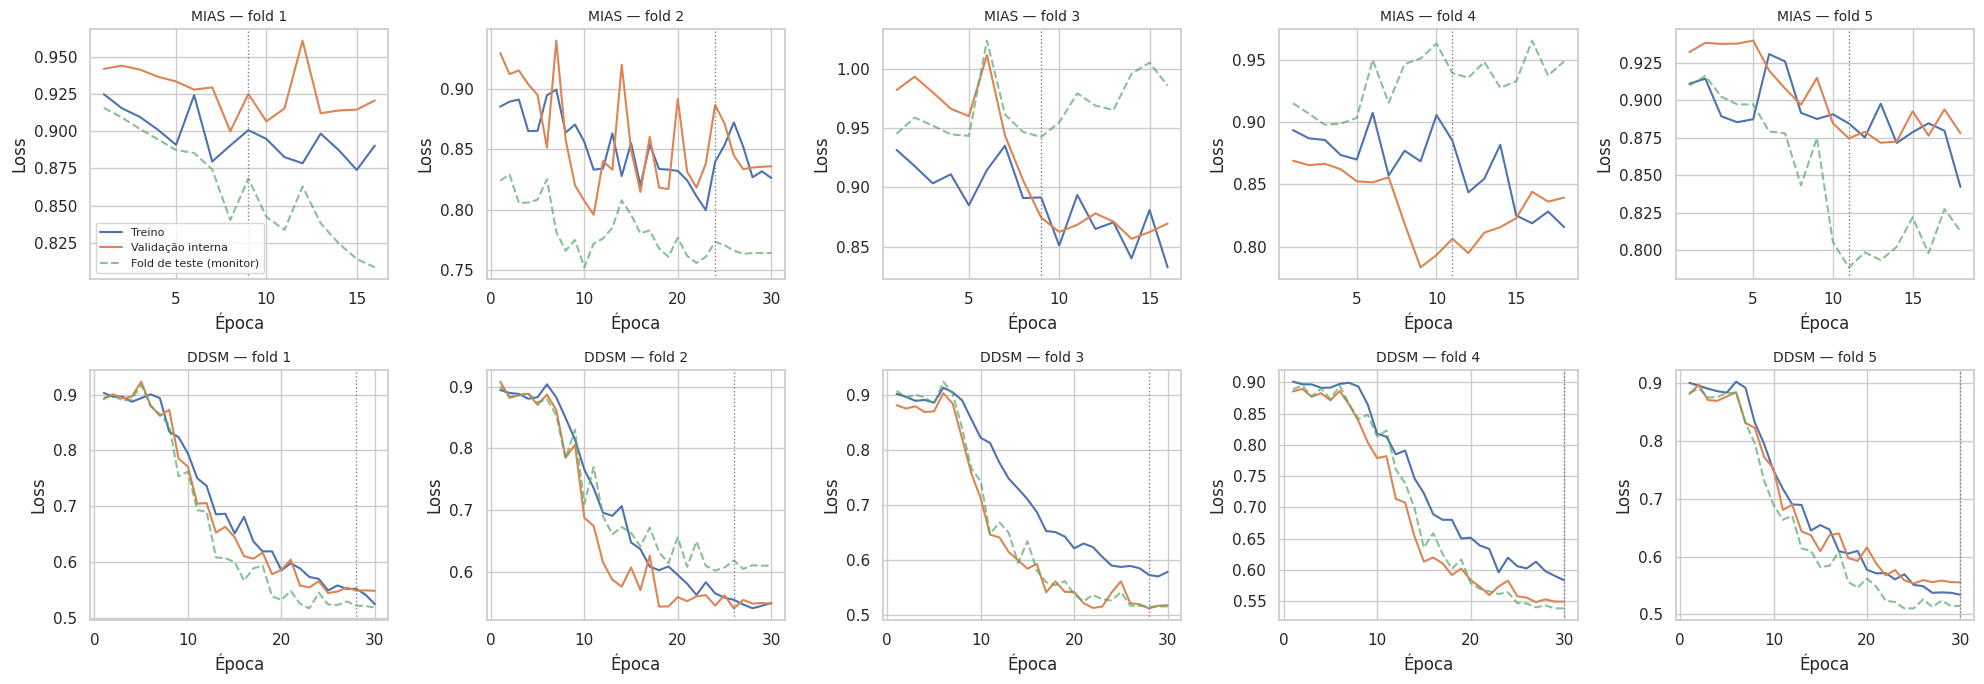

In [10]:
def run_experiment1(name, seed):
    d = DATA[name]
    X, y, g = d["X"], d["y"], d["groups"]
    outer = StratifiedGroupKFold(n_splits=CONFIG["N_SPLITS"], shuffle=True, random_state=seed)
    res = dict(folds=[], hist=[], oof=[])

    for fold, (tr_all, te) in enumerate(outer.split(X, y, g)):
        tr_in, va_in = group_holdout(y[tr_all], g[tr_all], seed + fold, CONFIG["INNER_VAL_FRAC"])
        tr, va = tr_all[tr_in], tr_all[va_in]
        # paciente em um só conjunto
        assert set(g[tr]).isdisjoint(g[va]) and set(g[tr]).isdisjoint(g[te]) and set(g[va]).isdisjoint(g[te])

        print(f"[{name}] fold {fold + 1}/{CONFIG['N_SPLITS']} | treino={len(tr)} val={len(va)} teste={len(te)}")
        model, hist = train_model(X, y, tr, va, seed + fold, mon_idx=te)

        p_va = predict_proba(model, X, y, va)
        thr = select_threshold(y[va], p_va)                  # limiar: validação interna
        p_te = predict_proba(model, X, y, te)
        m = compute_metrics(y[te], p_te, thr)

        b = hist.attrs["best_epoch"]
        row = hist[hist.epoch == b].iloc[0]
        m.update(dataset=name, fold=fold, best_epoch=b, gap_val_minus_train=row.val_loss - row.train_loss)
        res["folds"].append(m)
        res["hist"].append(hist)
        res["oof"].append(pd.DataFrame(dict(idx=te, y=y[te], p=p_te, pred=(p_te >= thr).astype(int),
                                            g=g[te], fold=fold)))
        print(f"  -> AUC={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    res["oof"] = pd.concat(res["oof"], ignore_index=True)
    return res


R1 = {}
for name in ["mias", "ddsm"]:
    R1[name] = run_experiment1(name, CONFIG["EXP1_SEED"])

with open(f"/content/drive/MyDrive/TCC/R1_swin_{CONFIG['POOLING']}_roi_clahe.pkl", "wb") as fh:
    pickle.dump(R1, fh)

# ---- Resumo: média ± dp entre folds ----
for name in ["mias", "ddsm"]:
    folds = pd.DataFrame(R1[name]["folds"])
    print(f"\n=== Experimento 1 — {name.upper()} (média ± dp entre {CONFIG['N_SPLITS']} folds) ===")
    display(mean_std_table(R1[name]["folds"]).to_frame("valor"))
    print(f"Gap Val − Treino (loss, na melhor época): "
          f"{folds.gap_val_minus_train.mean():.3f} ± {folds.gap_val_minus_train.std():.3f}")
    display(folds[["fold", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr",
                   "gap_val_minus_train"]].round(3))
    folds.to_csv(OUT / f"exp1_folds_{name}.csv", index=False)

# ---- Curvas de loss ----
fig, axes = plt.subplots(2, CONFIG["N_SPLITS"], figsize=(4 * CONFIG["N_SPLITS"], 7), squeeze=False)
for r, name in enumerate(["mias", "ddsm"]):
    for f, h in enumerate(R1[name]["hist"]):
        ax = axes[r, f]
        ax.plot(h.epoch, h.train_loss, label="Treino")
        ax.plot(h.epoch, h.val_loss, label="Validação interna")
        ax.plot(h.epoch, h.mon_loss, "--", alpha=0.7, label="Fold de teste (monitor)")
        ax.axvline(h.attrs["best_epoch"], color="gray", ls=":", lw=1)
        ax.set_title(f"{name.upper()} — fold {f + 1}", fontsize=10)
        ax.set_xlabel("Época")
        ax.set_ylabel("Loss")
        if r == 0 and f == 0:
            ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "exp1_loss_curves.png", dpi=150)
plt.show()

## 7. Experimento 2: domain shift direto

Treina em um dataset e avalia no outro inteiro, nos dois sentidos (mias → ddsm e ddsm → mias). Para cada semente, a origem é dividida por paciente em treino e validação interna. O limiar vem só da origem. Nada do destino entra no treino, na escolha da época ou no limiar.

In [11]:
def run_experiment2(src, tgt):
    Xs, ys, gs = DATA[src]["X"], DATA[src]["y"], DATA[src]["groups"]
    Xt, yt = DATA[tgt]["X"], DATA[tgt]["y"]
    out = dict(probs={}, thr={}, metrics=[], src_val=[])

    for s in CONFIG["SEEDS"]:
        tr, va = group_holdout(ys, gs, s, CONFIG["INNER_VAL_FRAC"])
        assert set(gs[tr]).isdisjoint(gs[va])
        print(f"[{src} -> {tgt}] seed {s} | treino={len(tr)} val={len(va)} | alvo={len(yt)}")
        model, hist = train_model(Xs, ys, tr, va, s, mon_idx=None)

        p_va = predict_proba(model, Xs, ys, va)
        thr = select_threshold(ys[va], p_va)                          # limiar: origem
        p_t = predict_proba(model, Xt, yt, np.arange(len(yt)))        # alvo inteiro
        m = compute_metrics(yt, p_t, thr)
        m.update(seed=s, direction=f"{src}->{tgt}", best_epoch=hist.attrs["best_epoch"])
        out["metrics"].append(m)
        out["src_val"].append(compute_metrics(ys[va], p_va, thr))
        out["probs"][s], out["thr"][s] = p_t, thr
        print(f"  -> AUC alvo={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr(origem)={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return out


R2 = {}
for src, tgt in [("mias", "ddsm"), ("ddsm", "mias")]:
    R2[(src, tgt)] = run_experiment2(src, tgt)

with open(f"/content/drive/MyDrive/TCC/R2_swin_{CONFIG['POOLING']}_roi_clahe.pkl", "wb") as fh:
    pickle.dump(R2, fh)

for (src, tgt), r in R2.items():
    print(f"\n=== Experimento 2 — {src.upper()} → {tgt.upper()} ({len(CONFIG['SEEDS'])} sementes) ===")
    df = pd.DataFrame(r["metrics"])
    display(df[["seed", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr"]].round(3))
    display(mean_std_table(r["metrics"]).to_frame("média ± dp"))
    df.to_csv(OUT / f"exp2_{src}_to_{tgt}.csv", index=False)

[mias -> ddsm] seed 42 | treino=273 val=45 | alvo=3716
  ep 01 | fase=head_only | LR=3.0e-04 | train 0.9203 | val 0.9383 | val AUC 0.450
  ep 02 | fase=head_only | LR=3.0e-04 | train 0.9023 | val 0.9422 | val AUC 0.494
  ep 03 | fase=head_only | LR=2.9e-04 | train 0.8953 | val 0.9275 | val AUC 0.538
  ep 04 | fase=head_only | LR=2.9e-04 | train 0.8864 | val 0.9252 | val AUC 0.584
  ep 05 | fase=head_only | LR=2.8e-04 | train 0.8903 | val 0.9148 | val AUC 0.616
  -> backbone descongelado; fine-tuning com LR discriminativa
  ep 06 | fase=fine_tuning | LR=1.0e-05,3.0e-04,1.0e-05 | train 0.9078 | val 0.9104 | val AUC 0.597
  ep 07 | fase=fine_tuning | LR=9.8e-06,3.0e-04,9.8e-06 | train 0.8797 | val 0.8836 | val AUC 0.674
  ep 08 | fase=fine_tuning | LR=9.6e-06,2.9e-04,9.6e-06 | train 0.8937 | val 0.8426 | val AUC 0.679
  ep 09 | fase=fine_tuning | LR=9.4e-06,2.8e-04,9.4e-06 | train 0.8887 | val 0.8670 | val AUC 0.668
  ep 10 | fase=fine_tuning | LR=9.0e-06,2.7e-04,9.0e-06 | train 0.9022 | 

,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,12,0.535,0.168,0.827,0.498,0.226,0.346,0.446
1,123,17,0.525,0.096,0.916,0.506,0.154,0.383,0.518
2,999,10,0.502,0.075,0.928,0.501,0.124,0.360,0.618


,média ± dp
auc,0.521 ± 0.017
sens,0.113 ± 0.049
spec,0.890 ± 0.055
bal_acc,0.502 ± 0.004
f1,0.168 ± 0.053
precision,0.363 ± 0.019



=== Experimento 2 — DDSM → MIAS (3 sementes) ===


,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,29,0.810,0.270,0.990,0.630,0.420,0.938,0.646
1,123,27,0.799,0.405,0.976,0.691,0.559,0.900,0.472
2,999,28,0.805,0.387,0.966,0.677,0.534,0.860,0.517


,média ± dp
auc,0.805 ± 0.006
sens,0.354 ± 0.073
spec,0.977 ± 0.012
bal_acc,0.666 ± 0.032
f1,0.504 ± 0.074
precision,0.899 ± 0.039


## 8. Análise

- **Drop** = AUC interno (Exp. 1) − AUC cruzado (Exp. 2).
- **IC 95 %:** bootstrap que reamostra pacientes, não imagens.
- **Predição cruzada agregada:** média das probabilidades entre sementes e média dos limiares de origem.
- **Limiar "oráculo":** usa rótulos do alvo. Só diagnóstico, não reportar como desempenho.

In [12]:
# ---- Bootstrap por paciente ----
def patient_bootstrap(y, p, groups, n_boot, seed):
    rng = np.random.RandomState(seed)
    ug, inv = np.unique(groups, return_inverse=True)
    by_g = [np.where(inv == i)[0] for i in range(len(ug))]
    vals = []
    for _ in range(n_boot):
        pick = rng.randint(0, len(ug), len(ug))
        idx = np.concatenate([by_g[i] for i in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    return np.array(vals)


def ci95(v):
    return np.percentile(v, [2.5, 97.5])


# ---- Predições internas (OOF) e cruzadas (ensemble) ----
OOF = {n: R1[n]["oof"] for n in ["mias", "ddsm"]}
CROSS = {}
for (src, tgt), r in R2.items():
    p_ens = np.mean([r["probs"][s] for s in CONFIG["SEEDS"]], axis=0)
    thr_ens = float(np.mean([r["thr"][s] for s in CONFIG["SEEDS"]]))
    CROSS[(src, tgt)] = dict(p=p_ens, thr=thr_ens, y=DATA[tgt]["y"], g=DATA[tgt]["groups"])

# ---- Tabela de generalização ----
rows = []
for (src, tgt) in R2:
    folds = pd.DataFrame(R1[src]["folds"])
    auc_int_fold = folds.auc.mean()
    o = OOF[src]
    auc_int_pool = roc_auc_score(o.y, o.p)
    b_int = patient_bootstrap(o.y.values, o.p.values, o.g.values, CONFIG["N_BOOT"], CONFIG["BOOT_SEED"])

    c = CROSS[(src, tgt)]
    seed_aucs = np.array([m["auc"] for m in R2[(src, tgt)]["metrics"]])
    auc_cross_ens = roc_auc_score(c["y"], c["p"])
    b_cr = patient_bootstrap(c["y"], c["p"], c["g"], CONFIG["N_BOOT"], CONFIG["BOOT_SEED"] + 1)

    m = min(len(b_int), len(b_cr))
    b_drop = b_int[:m] - b_cr[:m]
    drop_seed = auc_int_fold - seed_aucs
    lo_i, hi_i = ci95(b_int)
    lo_c, hi_c = ci95(b_cr)
    lo_d, hi_d = ci95(b_drop)
    rows.append({
        "Sentido": f"{src.upper()} → {tgt.upper()}",
        "AUC interno (média folds ± dp)": f"{auc_int_fold:.3f} ± {folds.auc.std():.3f}",
        "AUC interno OOF [IC95%]": f"{auc_int_pool:.3f} [{lo_i:.3f}, {hi_i:.3f}]",
        "AUC cruzado (sementes ± dp)": f"{seed_aucs.mean():.3f} ± {seed_aucs.std(ddof=1) if len(seed_aucs) > 1 else 0:.3f}",
        "AUC cruzado ensemble [IC95%]": f"{auc_cross_ens:.3f} [{lo_c:.3f}, {hi_c:.3f}]",
        "Drop (média folds − sementes ± dp)": f"{drop_seed.mean():.3f} ± {drop_seed.std(ddof=1) if len(drop_seed) > 1 else 0:.3f}",
        "Drop (OOF − ensemble) [IC95%]": f"{auc_int_pool - auc_cross_ens:.3f} [{lo_d:.3f}, {hi_d:.3f}]",
    })
gen_table = pd.DataFrame(rows).set_index("Sentido")
display(gen_table.T)
gen_table.to_csv(OUT / "generalization_summary.csv")

Sentido,MIAS → DDSM,DDSM → MIAS
AUC interno (média folds ± dp),0.665 ± 0.127,0.893 ± 0.015
AUC interno OOF [IC95%],"0.651 [0.587, 0.712]","0.891 [0.878, 0.904]"
AUC cruzado (sementes ± dp),0.521 ± 0.017,0.805 ± 0.006
AUC cruzado ensemble [IC95%],"0.525 [0.498, 0.548]","0.820 [0.769, 0.867]"
Drop (média folds − sementes ± dp),0.144 ± 0.017,0.089 ± 0.006
Drop (OOF − ensemble) [IC95%],"0.126 [0.055, 0.191]","0.071 [0.020, 0.124]"


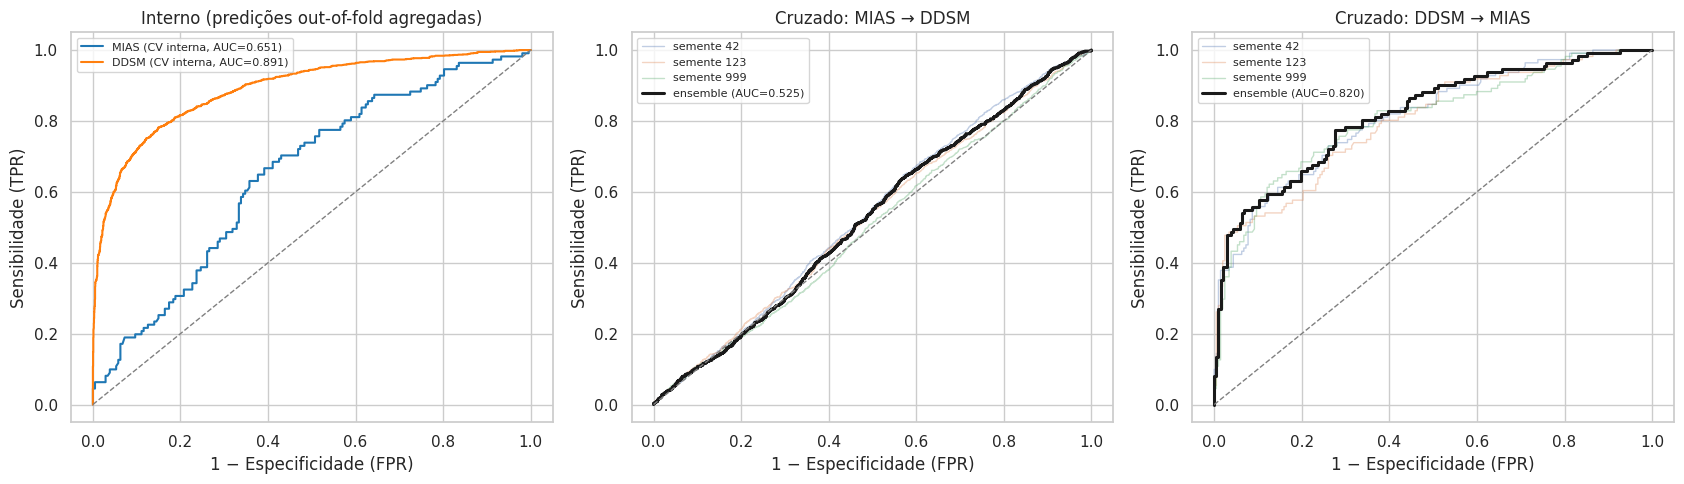

In [13]:
# ---- Curvas ROC ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
for n, col in [("mias", "tab:blue"), ("ddsm", "tab:orange")]:
    o = OOF[n]
    fpr, tpr, _ = roc_curve(o.y, o.p)
    ax.plot(fpr, tpr, color=col, label=f"{n.upper()} (CV interna, AUC={roc_auc_score(o.y, o.p):.3f})")
ax.set_title("Interno (predições out-of-fold agregadas)")

for ax, (src, tgt) in zip(axes[1:], R2):
    c = CROSS[(src, tgt)]
    for s in CONFIG["SEEDS"]:
        fpr, tpr, _ = roc_curve(c["y"], R2[(src, tgt)]["probs"][s])
        ax.plot(fpr, tpr, alpha=0.35, lw=1, label=f"semente {s}")
    fpr, tpr, _ = roc_curve(c["y"], c["p"])
    ax.plot(fpr, tpr, "k", lw=2.2, label=f"ensemble (AUC={roc_auc_score(c['y'], c['p']):.3f})")
    ax.set_title(f"Cruzado: {src.upper()} → {tgt.upper()}")

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    ax.set_xlabel("1 − Especificidade (FPR)")
    ax.set_ylabel("Sensibilidade (TPR)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "roc_curves.png", dpi=150)
plt.show()

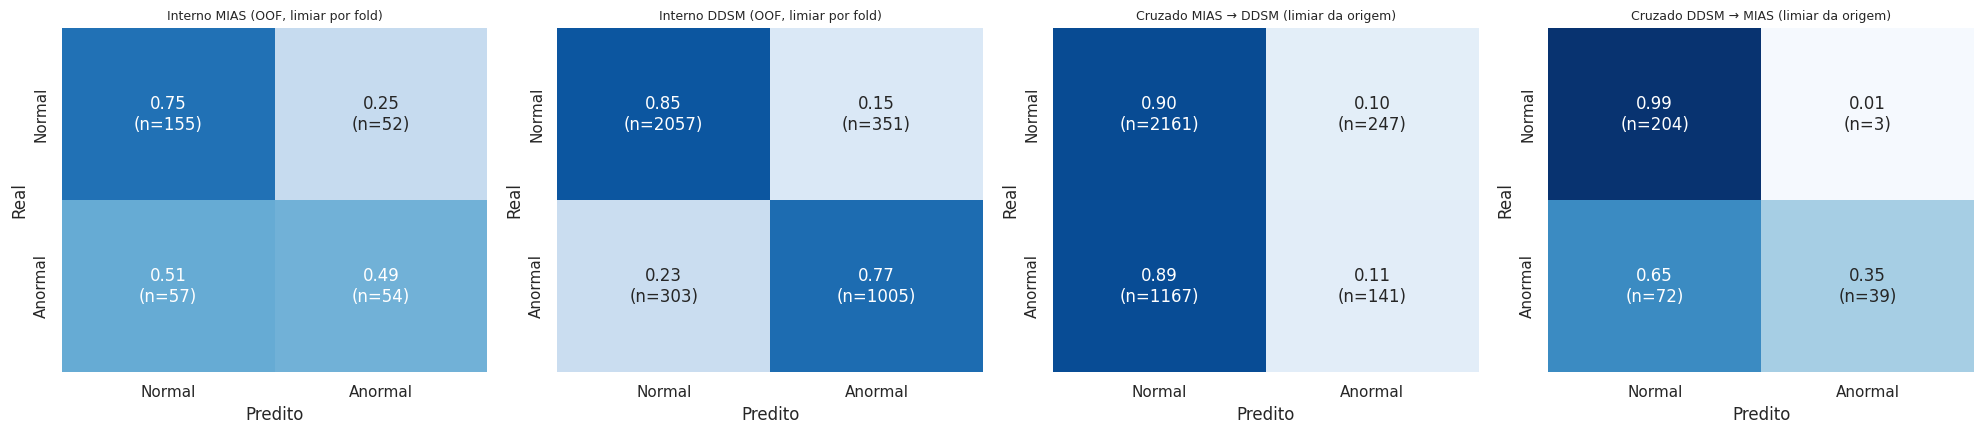

In [14]:
# ---- Matrizes de confusão ----
panels = [(f"Interno {n.upper()} (OOF, limiar por fold)", OOF[n].y.values, OOF[n].pred.values) for n in OOF]
panels += [(f"Cruzado {s.upper()} → {t.upper()} (limiar da origem)", CROSS[(s, t)]["y"],
            (CROSS[(s, t)]["p"] >= CROSS[(s, t)]["thr"]).astype(int)) for (s, t) in R2]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (title, yt_, yp_) in zip(axes, panels):
    cm = confusion_matrix(yt_, yp_, labels=[0, 1])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cmn[i, j]:.2f}\n(n={cm[i, j]})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["Normal", "Anormal"], yticklabels=["Normal", "Anormal"])
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

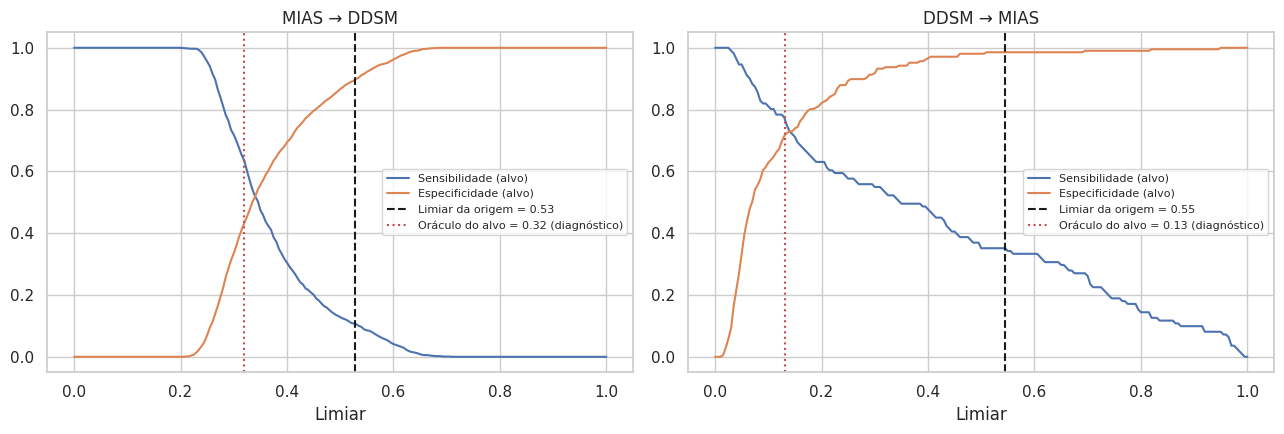

Sentido,MIAS → DDSM,DDSM → MIAS
Sens interna (origem),0.491,0.768
Esp interna (origem),0.755,0.854
Sens alvo @limiar origem,0.108,0.351
Esp alvo @limiar origem,0.897,0.986
Sens alvo @oráculo (diag.),0.637,0.775
Esp alvo @oráculo (diag.),0.433,0.725
Δ Sens (alvo − interna),-0.383,-0.417
Δ Esp (alvo − interna),0.142,0.132



Arquivos salvos em: /content/drive/MyDrive/TCC/outputs_roi_clahe_haar_trainable


In [15]:
# ---- Deslocamento de limiar ----
ths = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shift_rows = []
for ax, (src, tgt) in zip(axes, R2):
    c = CROSS[(src, tgt)]
    sens = [((c["p"] >= t) & (c["y"] == 1)).sum() / (c["y"] == 1).sum() for t in ths]
    spec = [((c["p"] < t) & (c["y"] == 0)).sum() / (c["y"] == 0).sum() for t in ths]
    ax.plot(ths, sens, label="Sensibilidade (alvo)")
    ax.plot(ths, spec, label="Especificidade (alvo)")
    ax.axvline(c["thr"], color="k", ls="--", label=f"Limiar da origem = {c['thr']:.2f}")
    t_or = select_threshold(c["y"], c["p"], "youden")   # só diagnóstico
    ax.axvline(t_or, color="r", ls=":", label=f"Oráculo do alvo = {t_or:.2f} (diagnóstico)")
    ax.set_title(f"{src.upper()} → {tgt.upper()}")
    ax.set_xlabel("Limiar")
    ax.legend(fontsize=8)

    internal = pd.DataFrame(R1[src]["folds"])
    mo = compute_metrics(c["y"], c["p"], c["thr"])
    mc = compute_metrics(c["y"], c["p"], t_or)
    shift_rows.append({"Sentido": f"{src.upper()} → {tgt.upper()}",
                       "Sens interna (origem)": internal.sens.mean(), "Esp interna (origem)": internal.spec.mean(),
                       "Sens alvo @limiar origem": mo["sens"], "Esp alvo @limiar origem": mo["spec"],
                       "Sens alvo @oráculo (diag.)": mc["sens"], "Esp alvo @oráculo (diag.)": mc["spec"]})
plt.tight_layout()
plt.savefig(OUT / "threshold_shift.png", dpi=150)
plt.show()

shift = pd.DataFrame(shift_rows).set_index("Sentido").round(3)
shift["Δ Sens (alvo − interna)"] = shift["Sens alvo @limiar origem"] - shift["Sens interna (origem)"]
shift["Δ Esp (alvo − interna)"] = shift["Esp alvo @limiar origem"] - shift["Esp interna (origem)"]
display(shift.T.round(3))
shift.to_csv(OUT / "threshold_shift.csv")
print(f"\nArquivos salvos em: {OUT.resolve()}")

## 9. Resumo das métricas

| Métrica | O que mede | Quando usar |
|---|---|---|
| **Acurácia** | Proporção de acertos gerais | Dados balanceados |
| **Precisão** | Confiabilidade das predições positivas | Evitar falsos positivos |
| **Recall** (sensibilidade) | Capacidade de encontrar positivos reais | Evitar falsos negativos |
| **F1-score** | Equilíbrio entre precisão e recall | Dados desbalanceados |
| **AUC-ROC** | Capacidade de separar as classes | Avaliação global do modelo |


In [16]:
# média ± dp entre folds (Exp. 1) ou sementes (Exp. 2)
COLS = {"acc": "Acurácia", "precision": "Precisão", "sens": "Recall", "f1": "F1-score", "auc": "AUC-ROC"}


def fmt(rows):
    df = pd.DataFrame(rows)[list(COLS)]
    return {v: f"{df[k].mean():.3f} ± {df[k].std():.3f}" for k, v in COLS.items()}


summary = {f"Exp. 1 — {n.upper()} (CV)": fmt(R1[n]["folds"]) for n in ["mias", "ddsm"]}
summary.update({f"Exp. 2 — {s.upper()} → {t.upper()}": fmt(r["metrics"]) for (s, t), r in R2.items()})
summary = pd.DataFrame(summary).T
display(summary)
summary.to_csv(OUT / "final_summary.csv")

,Acurácia,Precisão,Recall,F1-score,AUC-ROC
Exp. 1 — MIAS (CV),0.658 ± 0.092,0.548 ± 0.183,0.491 ± 0.142,0.496 ± 0.119,0.665 ± 0.127
Exp. 1 — DDSM (CV),0.824 ± 0.026,0.749 ± 0.065,0.768 ± 0.050,0.755 ± 0.019,0.893 ± 0.015
Exp. 2 — MIAS → DDSM,0.617 ± 0.019,0.363 ± 0.019,0.113 ± 0.049,0.168 ± 0.053,0.521 ± 0.017
Exp. 2 — DDSM → MIAS,0.760 ± 0.019,0.899 ± 0.039,0.354 ± 0.073,0.504 ± 0.074,0.805 ± 0.006
